In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')

In [3]:
import torch
import tqdm
from sklearn.metrics import classification_report
import numpy as np
from sklearn.metrics import confusion_matrix

In [4]:
seed = 1
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [5]:
from dataset import CANMLDataset


test_dataset = CANMLDataset(
        root_dir="../data/can-ml/can-ml/2017-subaru-forester/180826/preprocessed/rid3/TFRecord_w32_s32/", window_size=32, stride_size=32, is_train=False, is_test=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=True, pin_memory=True)

In [6]:
print(test_dataset.root_dir)
print(len(test_dataset))

../data/can-ml/can-ml/2017-subaru-forester/180826/preprocessed/rid3/TFRecord_w32_s32/
34947


In [7]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def draw_confusion_matrix(cm, classes, save_file=None):
    cm = np.array(cm, dtype=float)

    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    cm_ratio = cm / row_sums  # giữ [0,1], KHÔNG nhân 100

    cm_df = pd.DataFrame(cm_ratio, index=classes, columns=classes)
    annot_labels = cm_df.map(lambda x: f'{x:.4f}')  # "0.9980" - 4 chữ số thập phân

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_df, annot=annot_labels, fmt='', cmap='YlGnBu', cbar=False,
                linewidths=0.5, vmin=0, vmax=1)  # vmax=1 vì thang [0,1]
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    plt.tight_layout()
    if save_file:
        plt.savefig(save_file, dpi=200)
    plt.show()
    plt.close()
   

### Define model

In [13]:
from networks.conv_retnet import ConvRetNet


cnn_1d_retnet_model = ConvRetNet(
                num_features=9,
                d_model=128,
                out_channels_payload=128,
                window_size=32,
                num_layers=2,
                num_heads=4,
                ffn_dim=256,
                num_classes=10,
                dropout=0.1,
            )


In [14]:
model_path = '../save/CAN-ML_models/conv-id-aware-retnet-swiglu/conv-id-aware-retnet-swiglu_CAN-ML_2nd-running_lr_0.0003_decay_0.0001_bsz_128_trial_0_epochs_200/083126_123827/ckpt_epoch_200.pth'
ckpt = torch.load(model_path, weights_only=False)
state_dict = ckpt['model']
cnn_1d_retnet_model.load_state_dict(state_dict=ckpt['model'])

<All keys matched successfully>

In [15]:
from train_model import get_predict


total_pred = np.array([], dtype=int)
total_label = np.array([], dtype=int) 

cnn_1d_retnet_model = cnn_1d_retnet_model.cuda()
cnn_1d_retnet_model.eval()

with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.cuda(non_blocking=True)

        feats, outputs, projected = cnn_1d_retnet_model(images)
        
        pred = get_predict(outputs)

        if isinstance(pred, torch.Tensor):
            pred = pred.cpu().numpy()
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()

        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)



100%|██████████| 547/547 [00:02<00:00, 183.20it/s]


In [16]:
conf_matrix = confusion_matrix(total_label, total_pred)

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)
print("Confusion Matrix:\n", conf_matrix)



Classification Report:
               precision    recall  f1-score   support

      Normal     0.9981    0.9990    0.9985     29545
    Combined     0.9866    0.9753    0.9809      1581
         DoS     1.0000    1.0000    1.0000       267
       Fuzzy     0.9903    0.9903    0.9903       309
        Gear     0.9818    1.0000    0.9908       162
    Interval     0.9981    0.9981    0.9981      1543
         RPM     0.9915    0.9894    0.9904       470
       Speed     0.9884    0.9734    0.9808       526
  Standstill     1.0000    1.0000    1.0000       244
  Systematic     1.0000    0.9867    0.9933       300

    accuracy                         0.9972     34947
   macro avg     0.9935    0.9912    0.9923     34947
weighted avg     0.9972    0.9972    0.9972     34947

Confusion Matrix:
 [[29516    17     0     1     3     0     4     4     0     0]
 [   36  1542     0     0     0     1     0     2     0     0]
 [    0     0   267     0     0     0     0     0     0     0]
 [    3  

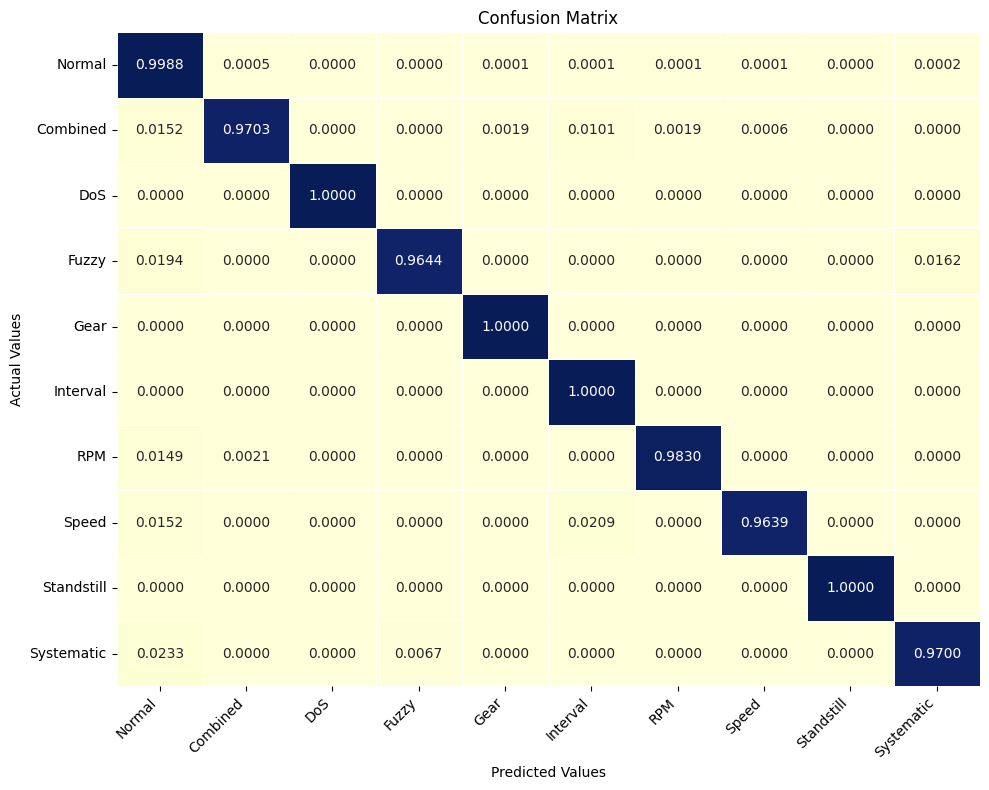

In [13]:
#### visualize confusion matrix
draw_confusion_matrix(conf_matrix, classes, save_file='../images/1D-CNN-RetNet-CE-dim=144/window=32+stride=32/gpaco_conf_matrix_040826')